<a href="https://colab.research.google.com/github/APenn215/MSBD-566-Predictive-Modeling/blob/main/Predicting_Cardiovascular_Disease__(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Data understanding**

In [ ]:
import pandas as pd
df = pd.read_csv('cardio_train.csv', sep=";")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 70000
Columns: 13


In [ ]:
# Any Missing values
df.isna().sum()


id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [ ]:
# repeated records?

print("Repeated IDs:", df["id"].duplicated().sum())
print("Repeated rows excluding ID:", df.drop(columns="id").duplicated().sum())

Repeated IDs: 0
Repeated rows excluding ID: 24


# **Data Preparation**



In [ ]:
# 1. Preserve original data and create one audit table
df_work = df.copy()
audit = df.copy()

# 2. Check categorical codes
expected_codes = {
    "gender": [1, 2],
    "cholesterol": [1, 2, 3],
    "gluc": [1, 2, 3],
    "smoke": [0, 1],
    "alco": [0, 1],
    "active": [0, 1],
    "cardio": [0, 1]
}

for col, allowed in expected_codes.items():
    audit[f"{col}_unexpected"] = ~df[col].isin(allowed)

    # Stop for review rather than silently changing unexpected codes
    assert not audit[f"{col}_unexpected"].any(), (
        f"Review unexpected values in {col}"
    )

# 3. Record the BP cleaning rules already used
for col in ["ap_hi", "ap_lo"]:
    audit[f"{col}_nonpositive"] = df[col] <= 0
    audit[f"{col}_1000_or_more"] = df[col] >= 1000

audit["bp_pair_uncertain"] = (
    df["ap_hi"].between(0, 1000, inclusive="neither") &
    df["ap_lo"].between(0, 1000, inclusive="neither") &
    (df["ap_lo"] >= df["ap_hi"])
)

audit["ap_hi_manual_error"] = df["ap_hi"].isin(
    [701, 806, 902, 906, 907, 909, 960]
)

# 4. Combine those decisions and apply them once
audit["ap_hi_set_missing"] = (
    audit["ap_hi_nonpositive"] |
    audit["ap_hi_1000_or_more"] |
    audit["bp_pair_uncertain"] |
    audit["ap_hi_manual_error"]
)

audit["ap_lo_set_missing"] = (
    audit["ap_lo_nonpositive"] |
    audit["ap_lo_1000_or_more"] |
    audit["bp_pair_uncertain"]
)

for col in ["ap_hi", "ap_lo"]:
    df_work.loc[audit[f"{col}_set_missing"], col] = float("nan")

# 5. Record unresolved measurements without changing them
# These are exploratory review boundaries, not clinical cutoffs.
review_ranges = {
    "ap_hi": (70, 250),
    "ap_lo": (40, 150),
    "height": (100, 220),
    "weight": (30, None)
}

for col, (lower, upper) in review_ranges.items():
    values = df_work[col]
    flag = values.notna() & (values < lower)

    if upper is not None:
        flag = flag | (values.notna() & (values > upper))

    audit[f"{col}_unresolved"] = flag

# 6. Express age in years and select model variables
df_work["age_years"] = df_work["age"] / 365.25

X = df_work.drop(columns=["id", "age", "cardio"])
y = df_work["cardio"].copy()

# Perserving the original values.

In [ ]:
summary = pd.DataFrame({
    "Original missing": df[["ap_hi", "ap_lo", "height", "weight"]]
        .isna().sum(),
    "After preparation missing": df_work[
        ["ap_hi", "ap_lo", "height", "weight"]
    ].isna().sum(),
    "Unresolved measurements": [
        audit[f"{col}_unresolved"].sum()
        for col in ["ap_hi", "ap_lo", "height", "weight"]
    ]
})

display(summary)

print("Records retained:", len(df_work))
print("Predictor shape:", X.shape)

print("Records with unresolved BP:",
      audit[["ap_hi_unresolved", "ap_lo_unresolved"]]
      .any(axis=1).sum())

assert len(df_work) == len(df), "Unexpected change in record count."

,Original missing,After preparation missing,Unresolved measurements
ap_hi,0,353,10
ap_lo,0,1251,42
height,0,0,30
weight,0,0,7


Records retained: 70000
Predictor shape: (70000, 11)
Records with unresolved BP: 50


# **Spliting Training and Testing Data**



In [ ]:
from sklearn.model_selection import GroupShuffleSplit
groups = pd.util.hash_pandas_object(X, index=False)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
Y_train = y.iloc[train_idx].copy()
Y_test = y.iloc[test_idx].copy()

print("Training records:", len(X_train))
print("Test Records:", len(X_test))

print("\nDisease Percentage:")
print("Training:", round(Y_train.mean() * 100, 2))
print("Test:", round(Y_test.mean() * 100, 2))

# Matching groups do not cross the split

assert set(groups.iloc[train_idx]).isdisjoint(
    set(groups.iloc[test_idx])
)

Training records: 56002
Test Records: 13998

Disease Percentage:
Training: 50.05
Test: 49.64


# **Exploratory Data Analysis**

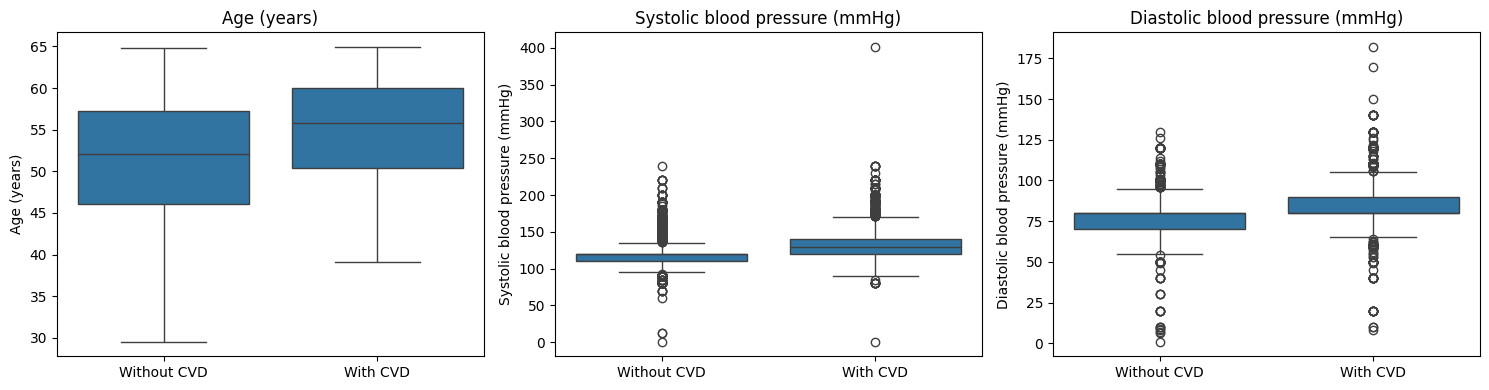

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine training predictors
train_eda = X_train.copy()
train_eda["CVD status"] = Y_train.map({
    0: "Without CVD",
    1: "With CVD"
})

# Plot age and blood pressure
plot_columns = {
    "age_years": "Age (years)",
    "ap_hi": "Systolic blood pressure (mmHg)",
    "ap_lo": "Diastolic blood pressure (mmHg)"
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (col, label) in zip(axes, plot_columns.items()):
    sns.boxplot(
        data=train_eda,
        x="CVD status",
        y=col,
        order=["Without CVD", "With CVD"],
        ax=ax
    )
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.set_title(label)

plt.tight_layout()
plt.show()

,Feature,Category,Records,CVD percentage
0,Cholesterol,Normal,41920,44.09
1,Cholesterol,Above normal,7642,60.00
2,Cholesterol,Well above normal,6440,77.03
3,Glucose,Normal,47558,48.09
4,Glucose,Above normal,4166,59.19
5,Glucose,Well above normal,4278,62.97
6,Smoking,No,51078,50.26
7,Smoking,Yes,4924,47.93
8,Alcohol use,No,52997,50.11
9,Alcohol use,Yes,3005,49.08


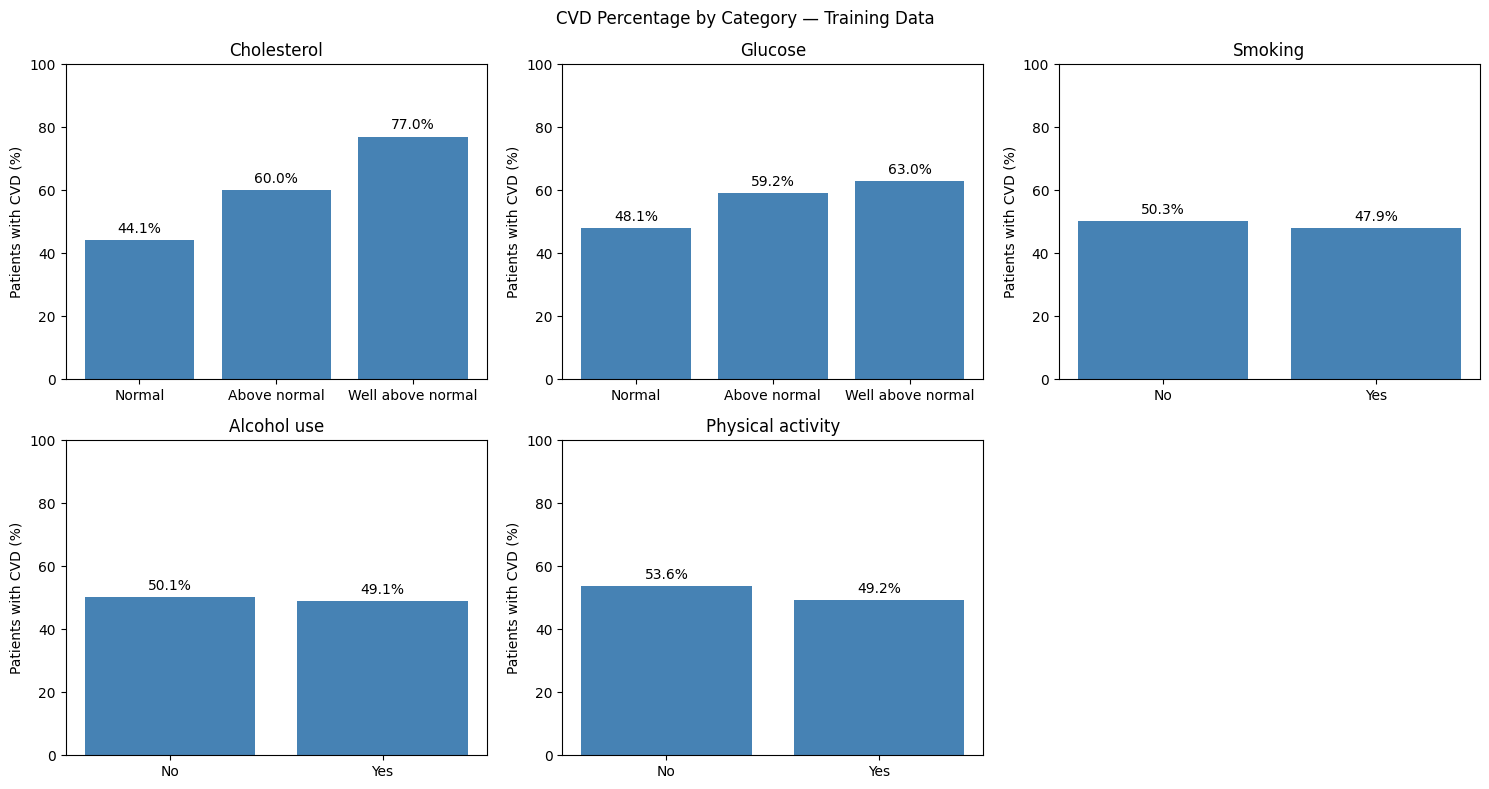

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

category_labels = {
    "cholesterol": {1: "Normal", 2: "Above normal", 3: "Well above normal"},
    "gluc": {1: "Normal", 2: "Above normal", 3: "Well above normal"},
    "smoke": {0: "No", 1: "Yes"},
    "alco": {0: "No", 1: "Yes"},
    "active": {0: "No", 1: "Yes"}
}

titles = {
    "cholesterol": "Cholesterol",
    "gluc": "Glucose",
    "smoke": "Smoking",
    "alco": "Alcohol use",
    "active": "Physical activity"
}

tables = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (feature, labels) in zip(axes.flat, category_labels.items()):
    # Calculate record counts and CVD percentages (using Y_train instead of y_train)
    summary = (
        Y_train.groupby(X_train[feature])
        .agg(Records="count", CVD_percentage="mean")
        .sort_index()
    )
    summary["CVD_percentage"] *= 100

    # Prepare the table
    table = summary.reset_index()
    table.columns = ["Category", "Records", "CVD percentage"]
    table["Category"] = table["Category"].map(labels)
    table.insert(0, "Feature", titles[feature])
    table["CVD percentage"] = table["CVD percentage"].round(2)
    tables.append(table)

    # Draw the bar graph using the same results
    bars = ax.bar(
        [labels[code] for code in summary.index],
        summary["CVD_percentage"],
        color="steelblue"
    )
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_title(titles[feature])
    ax.set_ylabel("Patients with CVD (%)")
    ax.set_ylim(0, 100)

# Display the combined table
display(pd.concat(tables, ignore_index=True))

# Display the graphs
axes.flat[-1].set_visible(False)
fig.suptitle("CVD Percentage by Category — Training Data")
plt.tight_layout()
plt.show()

# **Preprocessing Pipeline**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Define numeric and categorical features
numeric_features = [
    "age_years", "height", "weight", "ap_hi", "ap_lo"
]

categorical_features = [
    "gender", "cholesterol", "gluc", "smoke", "alco", "active"
]

# 2. Numeric prep  Logistic Regression
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Categorical prep
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# 4. Combine preparation steps for Logistic Regression
preprocessor_lr = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 5. Tree models use the same preparation without numeric scaling
preprocessor_tree = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


Logistic regression

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score
)

# Same validation folds for all three models
train_groups = groups.loc[X_train.index]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use capital Y_train instead of y_train
cv_splits = list(cv.split(X_train, Y_train, groups=train_groups))

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc"
}

# Reusable evaluation function
def evaluate_model(name, pipeline):
    scores = cross_validate(
        pipeline,
        X_train,
        Y_train, # Use capital Y_train instead of y_train
        cv=cv_splits,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    result = {"Model": name}
    for metric in scoring:
        result[metric] = scores[f"test_{metric}"].mean()

    result["ROC-AUC fold SD"] = scores["test_ROC-AUC"].std(ddof=1)
    return pd.DataFrame([result])

# Create and evaluate Logistic Regression
logistic_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor_lr)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_results = evaluate_model("Logistic Regression", logistic_pipeline)
display(lr_results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC fold SD
0,Logistic Regression,0.729,0.757,0.675,0.714,0.793,0.006


# Confusion Matrix for Logistic Regression

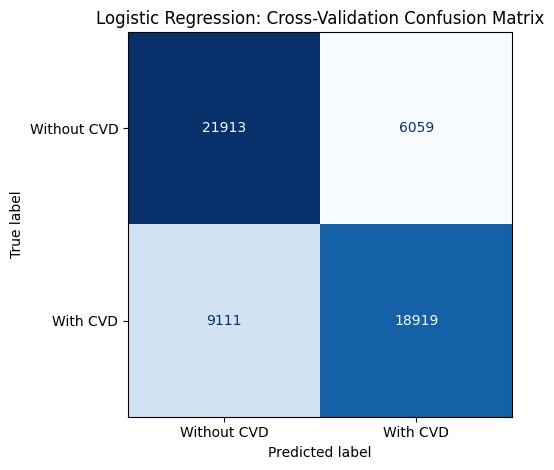

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict each training record using a model that did not train on its fold
validation_predictions = cross_val_predict(
    logistic_pipeline,
    X_train,
    Y_train, # Changed y_train to Y_train
    cv=cv_splits,
    method="predict",
    n_jobs=-1
)

# Display the combined validation confusion matrix
ConfusionMatrixDisplay.from_predictions(
    Y_train, # Changed y_train to Y_train
    validation_predictions,
    labels=[0, 1],
    display_labels=["Without CVD", "With CVD"],
    cmap="Blues",
    colorbar=False
)

plt.title("Logistic Regression: Cross-Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier

candidates = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": Pipeline([
        ("preprocessing", clone(preprocessor_tree)),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5,
            n_jobs=-1, random_state=42))
    ]),
    "HistGradientBoosting": Pipeline([
        ("preprocessing", clone(preprocessor_tree)),
        ("model", HistGradientBoostingClassifier(random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocessing", clone(preprocessor_tree)),
        ("model", XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=4,
            eval_metric="logloss", n_jobs=-1, random_state=42))
    ]),
}

results = pd.concat(
    [evaluate_model(name, pipe) for name, pipe in candidates.items()],
    ignore_index=True
).sort_values("ROC-AUC", ascending=False)

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC fold SD
3,XGBoost,0.735,0.756,0.696,0.725,0.802,0.007
2,HistGradientBoosting,0.734,0.753,0.698,0.724,0.801,0.006
1,Random Forest,0.734,0.752,0.700,0.725,0.799,0.007
0,Logistic Regression,0.729,0.757,0.675,0.714,0.793,0.006


In [ ]:
# 1. Add engineered features to train and test
for d in (X_train, X_test):
    d["bmi"] = d["weight"] / (d["height"] / 100) ** 2
    d["pulse_pressure"] = d["ap_hi"] - d["ap_lo"]
    d["map"] = d["ap_lo"] + (d["ap_hi"] - d["ap_lo"]) / 3

# 2. Rebuild the numeric preprocessing with the new columns
numeric_features = ["age_years", "height", "weight", "ap_hi", "ap_lo",
                    "bmi", "pulse_pressure", "map"]

preprocessor_lr = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
preprocessor_tree = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 3. Swap the new preprocessors into every candidate
for name, pipe in candidates.items():
    pipe.set_params(preprocessing=clone(
        preprocessor_lr if name == "Logistic Regression" else preprocessor_tree))

# 4. Rerun the comparison
results_fe = pd.concat(
    [evaluate_model(name, pipe) for name, pipe in candidates.items()],
    ignore_index=True
).sort_values("ROC-AUC", ascending=False)

display(results_fe.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC fold SD
3,XGBoost,0.735,0.755,0.695,0.724,0.802,0.006
2,HistGradientBoosting,0.735,0.752,0.702,0.726,0.801,0.006
1,Random Forest,0.734,0.752,0.698,0.724,0.798,0.006
0,Logistic Regression,0.729,0.757,0.675,0.714,0.793,0.006


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

search_spaces = {
    "XGBoost": {
        "model__n_estimators": randint(200, 800),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(3, 8),
        "model__min_child_weight": randint(1, 20),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.6, 0.4),
        "model__reg_lambda": loguniform(1e-2, 10),
    },
    "HistGradientBoosting": {
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_iter": randint(100, 500),
        "model__max_depth": [None, 3, 4, 6, 8],
        "model__min_samples_leaf": randint(20, 200),
        "model__l2_regularization": loguniform(1e-3, 10),
    },
}

tuned = {}
rows = []
for name, space in search_spaces.items():
    rs = RandomizedSearchCV(
        candidates[name], space,
        n_iter=20, scoring="roc_auc", cv=cv_splits,
        refit=True, n_jobs=1, random_state=42, verbose=1
    )
    rs.fit(X_train, Y_train)
    tuned[name] = rs
    rows.append({"Model": name + " (tuned)", "CV ROC-AUC": rs.best_score_})
    print(name, "best params:", rs.best_params_)

display(pd.DataFrame(rows).sort_values("CV ROC-AUC", ascending=False).round(4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
XGBoost best params: {'model__colsample_bytree': np.float64(0.9022204554172195), 'model__learning_rate': np.float64(0.01984601321734508), 'model__max_depth': 5, 'model__min_child_weight': 19, 'model__n_estimators': 285, 'model__reg_lambda': np.float64(4.379288100052081), 'model__subsample': np.float64(0.8497416192535173)}
Fitting 5 folds for each of 20 candidates, totalling 100 fits
HistGradientBoosting best params: {'model__l2_regularization': np.float64(0.12563152773938666), 'model__learning_rate': np.float64(0.03313073862781126), 'model__max_depth': 6, 'model__max_iter': 287, 'model__min_samples_leaf': 34}


,Model,CV ROC-AUC
0,XGBoost (tuned),0.8026
1,HistGradientBoosting (tuned),0.8020


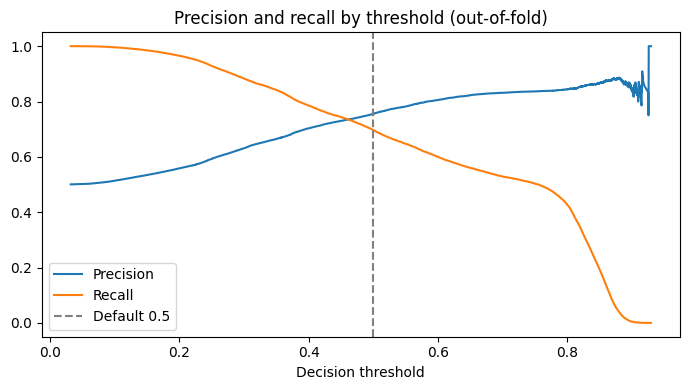

,Target recall,Threshold,Recall,Precision,Missed CVD %
0,0.70,0.497,0.70,0.754,30.0
1,0.75,0.441,0.75,0.726,25.0
2,0.80,0.384,0.80,0.692,20.0
3,0.85,0.340,0.85,0.659,15.0
4,0.90,0.282,0.90,0.617,10.0


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

best_name = "XGBoost"
best_model = tuned[best_name].best_estimator_

# Out-of-fold probabilities on the training data only
oof_proba = cross_val_predict(
    best_model, X_train, Y_train, cv=cv_splits,
    method="predict_proba", n_jobs=1
)[:, 1]

prec, rec, thr = precision_recall_curve(Y_train, oof_proba)

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(0.5, ls="--", c="gray", label="Default 0.5")
plt.xlabel("Decision threshold")
plt.legend()
plt.title("Precision and recall by threshold (out-of-fold)")
plt.tight_layout()
plt.show()

# Show the tradeoff at several recall targets
rows = []
for target in [0.70, 0.75, 0.80, 0.85, 0.90]:
    ok = rec[:-1] >= target
    t = thr[ok].max()
    i = np.where(thr == t)[0][0]
    rows.append({"Target recall": target, "Threshold": round(t, 3),
                 "Recall": round(rec[i], 3), "Precision": round(prec[i], 3),
                 "Missed CVD %": round((1 - rec[i]) * 100, 1)})
display(pd.DataFrame(rows))

,Threshold,Value,Accuracy,Precision,Recall,F1,ROC-AUC
0,Default (0.5),0.500,0.739,0.757,0.698,0.726,0.802
1,Chosen threshold,0.384,0.718,0.686,0.798,0.738,0.802


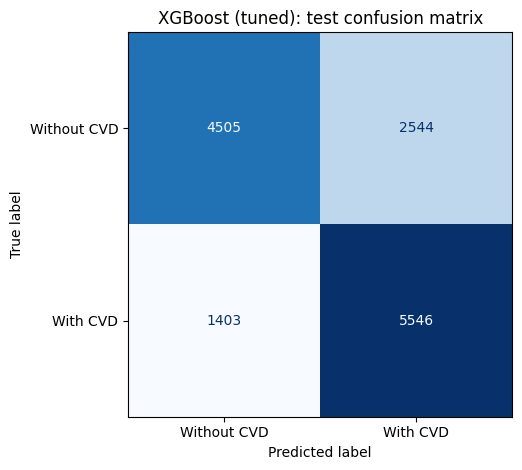

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

chosen_threshold = 0.384   # <- swap in 0.340 for the 85% row, etc.

best_model.fit(X_train, Y_train)
test_proba = best_model.predict_proba(X_test)[:, 1]

rows = []
for label, t in [("Default (0.5)", 0.5), ("Chosen threshold", chosen_threshold)]:
    pred = (test_proba >= t).astype(int)
    rows.append({
        "Threshold": label, "Value": round(t, 3),
        "Accuracy": accuracy_score(Y_test, pred),
        "Precision": precision_score(Y_test, pred),
        "Recall": recall_score(Y_test, pred),
        "F1": f1_score(Y_test, pred),
        "ROC-AUC": roc_auc_score(Y_test, test_proba),
    })
display(pd.DataFrame(rows).round(3))

ConfusionMatrixDisplay.from_predictions(
    Y_test, (test_proba >= chosen_threshold).astype(int),
    display_labels=["Without CVD", "With CVD"], cmap="Blues", colorbar=False)
plt.title("XGBoost (tuned): test confusion matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import OneHotEncoder

orig_numeric = ["age_years", "height", "weight", "ap_hi", "ap_lo"]

cat_interp = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", sparse_output=False))
])

pre_interp = ColumnTransformer([
    ("numeric", numeric_pipeline, orig_numeric),
    ("categorical", cat_interp, categorical_features)
])

lr_interp = Pipeline([
    ("preprocessing", pre_interp),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
]).fit(X_train, Y_train)

names = lr_interp.named_steps["preprocessing"].get_feature_names_out()
coefs = lr_interp.named_steps["model"].coef_[0]

or_table = (pd.DataFrame({
    "Feature": names,
    "Coefficient": coefs,
    "Odds ratio": np.exp(coefs)
}).sort_values("Odds ratio", ascending=False))

display(or_table.round(3))

,Feature,Coefficient,Odds ratio
7,categorical__cholesterol_3,1.098,2.999
3,numeric__ap_hi,0.954,2.596
6,categorical__cholesterol_2,0.362,1.437
0,numeric__age_years,0.344,1.411
2,numeric__weight,0.165,1.179
4,numeric__ap_lo,0.108,1.115
8,categorical__gluc_2,0.026,1.026
5,categorical__gender_2,-0.029,0.972
1,numeric__height,-0.029,0.972
10,categorical__smoke_1,-0.133,0.875


Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 556 kB 1.9 MB/s eta 0:00:01
     |████████████████████████████████| 80 kB 24.9 MB/s eta 0:00:01
     |████████████████████████████████| 2.7 MB 23.4 MB/s eta 0:00:01
     |████████████████████████████████| 28.8 MB 22.8 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


/Users/orlandopender/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


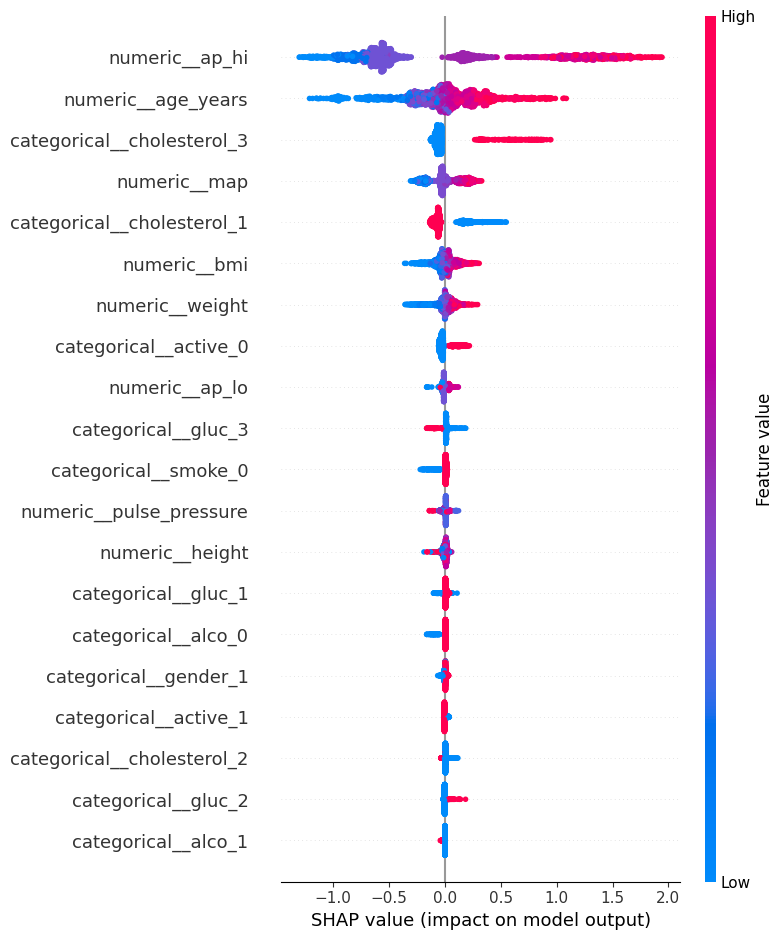

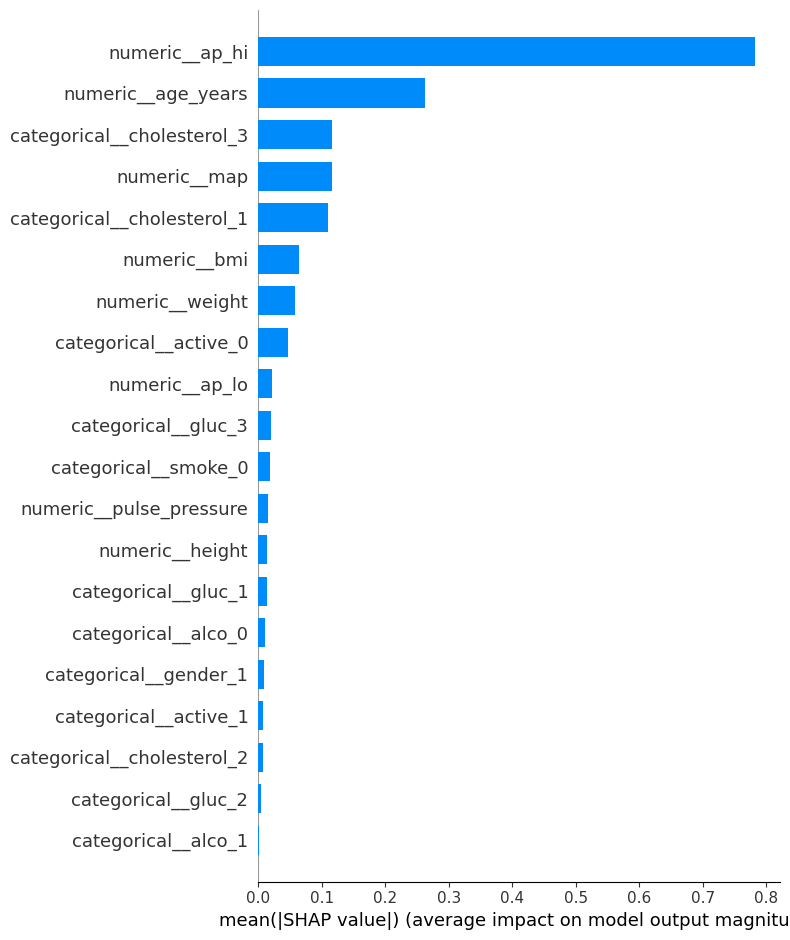

In [ ]:
%pip install shap
import shap

pre = best_model.named_steps["preprocessing"]
xgb = best_model.named_steps["model"]

# Explain a sample of the test set (faster, and plenty for stable plots)
X_sample = X_test.sample(2000, random_state=42)
X_trans = pd.DataFrame(pre.transform(X_sample),
                       columns=pre.get_feature_names_out())

explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_trans)

# 1. Beeswarm: importance plus direction of each feature's effect
shap.summary_plot(shap_values.values, X_trans, show=False)
plt.tight_layout()
plt.show()

# 2. Bar chart: mean absolute impact per feature
shap.summary_plot(shap_values.values, X_trans, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

,Group,Mean |SHAP|,Features
0,Blood pressure,0.904,4
1,Age,0.263,1
2,Cholesterol,0.209,3
3,Body size,0.118,3
4,Physical activity,0.054,2
5,Glucose,0.031,3
6,Smoking,0.019,2
7,Alcohol,0.012,2
8,Gender,0.010,2


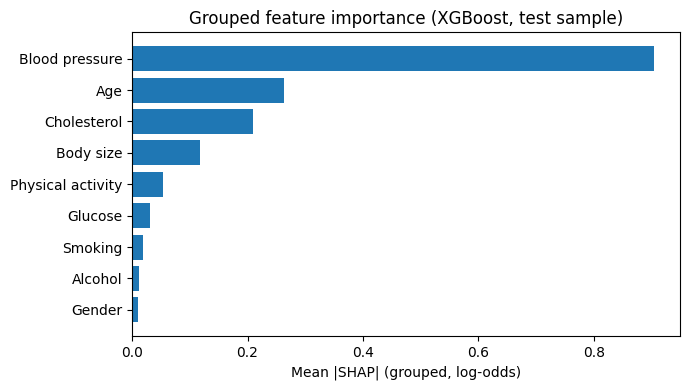

In [ ]:
groups_map = {
    "Blood pressure": ["ap_hi", "ap_lo", "map", "pulse_pressure"],
    "Age": ["age_years"],
    "Cholesterol": ["cholesterol"],
    "Body size": ["bmi", "weight", "height"],
    "Physical activity": ["active"],
    "Glucose": ["gluc"],
    "Smoking": ["smoke"],
    "Alcohol": ["alco"],
    "Gender": ["gender"],
}

cols = list(X_trans.columns)
sv = shap_values.values

rows = []
for group, keys in groups_map.items():
    idx = [i for i, c in enumerate(cols)
           if any(c.split("__", 1)[1] == k or c.split("__", 1)[1].startswith(k + "_")
                  for k in keys)]
    group_shap = sv[:, idx].sum(axis=1)          # per-patient group effect
    rows.append({"Group": group,
                 "Mean |SHAP|": np.abs(group_shap).mean(),
                 "Features": len(idx)})

group_table = (pd.DataFrame(rows)
               .sort_values("Mean |SHAP|", ascending=False)
               .reset_index(drop=True))
display(group_table.round(3))

# Check that every column landed in exactly one group
assert group_table["Features"].sum() == len(cols), "A feature was missed or double counted"

plt.figure(figsize=(7, 4))
plt.barh(group_table["Group"][::-1], group_table["Mean |SHAP|"][::-1])
plt.xlabel("Mean |SHAP| (grouped, log-odds)")
plt.title("Grouped feature importance (XGBoost, test sample)")
plt.tight_layout()
plt.show()